In [40]:
# https://github.com/jeandeducla/ML-Time-Series/blob/master/SVM-Accelerometer.ipynb
import pandas as pd
import numpy as np
import datetime as dt

In [41]:
import scipy.stats as st
from scipy.fftpack import fft, fftfreq 
from scipy.signal import argrelextrema
import operator

In [42]:
df=pd.read_csv('Gas_final_proccessed_data.csv')

In [43]:
df.head()

,Unnamed: 0,timestamp,temperature,CO2MG811Value,CO2CosIRValue,COValue,humidity,MOX1,MOX2,MOX3,MOX4
0,0,2019-11-06 11:37:13.038174+01:00,19.279728,566.36285,132.98889,116.453760,54.957638,472.04703,702.73663,640.57790,575.01337
1,1,2019-11-06 11:37:32.744996+01:00,19.836800,569.12670,125.11454,113.874990,54.505672,475.68230,702.80250,638.88275,573.16345
2,2,2019-11-06 11:37:53.018087+01:00,19.804783,566.53906,120.86817,120.774580,53.291725,477.43146,702.56683,642.23140,568.30700
3,3,2019-11-06 11:38:13.093151+01:00,19.905775,566.53906,120.75021,120.190520,53.291725,477.17900,702.56683,642.85800,566.78894
4,4,2019-11-06 11:38:33.032832+01:00,19.284597,567.17017,124.58858,118.695435,52.673695,482.03793,702.89370,643.02160,567.34310


In [44]:
del df['Unnamed: 0']

In [45]:
# need to convert time string to time format for easy processing
df['recordtime'] = df['timestamp']
df.recordtime =df.recordtime.apply(lambda x: pd.to_datetime(x).strftime("%Y-%m-%d %H:%M:%S"))
df.recordtime =df.recordtime.apply(lambda x: dt.datetime.strptime(x, "%Y-%m-%d %H:%M:%S"))

In [46]:
# sort values from small time to large time
# how much signal is difference from the prevous time to current time is important
df.sort_values(by='recordtime', inplace=True, ascending=True)
df['timestamp'] = pd.to_datetime(df['timestamp'])
df['timestamp'] = df['timestamp'].dt.floor(freq='2H')

In [47]:
# always check the latest data
df.head()

,timestamp,temperature,CO2MG811Value,CO2CosIRValue,COValue,humidity,MOX1,MOX2,MOX3,MOX4,recordtime
0,2019-11-06 10:00:00+01:00,19.279728,566.36285,132.98889,116.453760,54.957638,472.04703,702.73663,640.57790,575.01337,2019-11-06 11:37:13
1,2019-11-06 10:00:00+01:00,19.836800,569.12670,125.11454,113.874990,54.505672,475.68230,702.80250,638.88275,573.16345,2019-11-06 11:37:32
2,2019-11-06 10:00:00+01:00,19.804783,566.53906,120.86817,120.774580,53.291725,477.43146,702.56683,642.23140,568.30700,2019-11-06 11:37:53
3,2019-11-06 10:00:00+01:00,19.905775,566.53906,120.75021,120.190520,53.291725,477.17900,702.56683,642.85800,566.78894,2019-11-06 11:38:13
4,2019-11-06 10:00:00+01:00,19.284597,567.17017,124.58858,118.695435,52.673695,482.03793,702.89370,643.02160,567.34310,2019-11-06 11:38:33


In [48]:
df.tail()

,timestamp,temperature,CO2MG811Value,CO2CosIRValue,COValue,humidity,MOX1,MOX2,MOX3,MOX4,recordtime
416148,2020-02-13 10:00:00+01:00,20.405073,514.07404,45.662525,144.58173,57.716167,526.93677,700.0244,645.58673,582.87445,2020-02-13 11:56:53
416149,2020-02-13 10:00:00+01:00,20.391659,513.78320,45.992730,140.83190,57.716167,527.18530,700.0244,645.58673,583.03613,2020-02-13 11:57:14
416150,2020-02-13 10:00:00+01:00,20.391659,513.78320,45.992730,140.83190,57.716167,527.18530,700.0244,645.58673,583.03613,2020-02-13 11:57:33
416151,2020-02-13 10:00:00+01:00,20.391659,512.17114,45.992730,140.83190,57.723625,527.18530,700.4342,645.58673,583.03613,2020-02-13 11:57:54
416152,2020-02-13 10:00:00+01:00,20.391659,512.17114,45.992730,140.83190,57.723625,527.18530,700.4342,645.58673,583.03613,2020-02-13 11:58:14


In [49]:
df.shape

(416153, 11)

In [50]:
# look the count for each time group
group_count = pd.DataFrame(df.groupby('timestamp').count()['humidity'])
group_count.reset_index(inplace=True)
group_count.rename(columns={"humidity": "countv"}, inplace=True)

In [51]:
# some of the time group has low number of data missing
# Fillup them
group_count.countv.unique()

array([ 69, 360, 359, 361, 357, 350, 351,   5,  83, 358, 352, 342, 355,
       282, 335, 248, 326, 328,  47, 274, 243])

In [52]:
# these time group has low count - 
# lot of data is missing for these. So they need to be removed
time_low_count = group_count[group_count.countv<300]
time_low_count

,timestamp,countv
0,2019-11-06 10:00:00+01:00,69
389,2019-12-08 20:00:00+01:00,5
390,2019-12-09 10:00:00+01:00,83
960,2020-01-25 22:00:00+01:00,282
964,2020-01-26 06:00:00+01:00,248
1052,2020-02-02 14:00:00+01:00,47
1053,2020-02-04 12:00:00+01:00,274
1072,2020-02-06 02:00:00+01:00,243


In [53]:
# np.unique([(list(df.recordtime)[i] - list(df.recordtime)[i-1]).seconds for i in range(1, len(df.recordtime))])

In [54]:
df.columns

Index(['timestamp', 'temperature', 'CO2MG811Value', 'CO2CosIRValue', 'COValue',
       'humidity', 'MOX1', 'MOX2', 'MOX3', 'MOX4', 'recordtime'],
      dtype='object')

In [55]:
# investigate how these data is missing
processed_df = df[['temperature', 'humidity', 'CO2CosIRValue','CO2MG811Value', 'MOX1', 'MOX2', 'MOX3', 'MOX4', 'COValue']].copy()
processed_df['timestamp'] = df['timestamp']
processed_df['recordtime'] = df['recordtime']

In [56]:
# ndf = pd.DataFrame(columns=df.columns)
# for time in df.recordtime:
#     current_value = list(df[df.recordtime==time].values[0])
#     ndf.loc[len(ndf)] = current_value

#     next_time = time + dt.timedelta(seconds=22)
#     temp = df[(df.recordtime>time) & (df.recordtime<=next_time)]

#     if len(temp) < 1:
#         current_value[-1] = next_time
#         ndf.loc[len(ndf)] = current_value

#         next_time = next_time + dt.timedelta(seconds=22)
#         temp = df[(df.recordtime>time) & (df.recordtime<=next_time)]

#         if len(temp) < 1:
#             current_value[-1] = next_time
#             ndf.loc[len(ndf)] = current_value

In [57]:
processed_df=processed_df[~processed_df.timestamp.isin(time_low_count.timestamp)]

In [58]:
processed_df.shape

(414902, 11)

In [59]:
group_count = group_count[~group_count.timestamp.isin(time_low_count.timestamp)]

In [60]:
group_count.shape

(1153, 2)

In [61]:
def stat_area_features(x, Te=1.0):

    mean_ts = np.mean(x, axis=1).reshape(-1,1) # mean
    max_ts = np.amax(x, axis=1).reshape(-1,1) # max
    min_ts = np.amin(x, axis=1).reshape(-1,1) # min
    std_ts = np.std(x, axis=1).reshape(-1,1) # std
    skew_ts = st.skew(x, axis=1).reshape(-1,1) # skew
    kurtosis_ts = st.kurtosis(x, axis=1).reshape(-1,1) # kurtosis 
    iqr_ts = st.iqr(x, axis=1).reshape(-1,1) # interquartile rante
    mad_ts = np.median(np.sort(abs(x - np.median(x, axis=1).reshape(-1,1)),
                               axis=1), axis=1).reshape(-1,1) # median absolute deviation
    area_ts = np.trapz(x, axis=1, dx=Te).reshape(-1,1) # area under curve
    sq_area_ts = np.trapz(x ** 2, axis=1, dx=Te).reshape(-1,1) # area under curve ** 2

    return np.concatenate((mean_ts,max_ts,min_ts,std_ts,skew_ts,kurtosis_ts,
                           iqr_ts,mad_ts,area_ts,sq_area_ts), axis=1)

In [62]:
def frequency_domain_features(x, Te=1.0):

    # As the DFT coefficients and their corresponding frequencies are symetrical arrays
    # with respect to the middle of the array we need to know if the number of readings 
    # in x is even or odd to then split the arrays...
    if x.shape[1]%2 == 0:
        N = int(x.shape[1]/2)
    else:
        N = int(x.shape[1]/2) - 1
    xf = np.repeat(fftfreq(x.shape[1],d=Te)[:N].reshape(1,-1), x.shape[0], axis=0) # frequencies
    dft = np.abs(fft(x, axis=1))[:,:N] # DFT coefficients   
    
    # statistical and area features
    dft_features = stat_area_features(dft, Te=1.0)
    # weighted mean frequency
    dft_weighted_mean_f = np.average(xf, axis=1, weights=dft).reshape(-1,1)
    # 5 first DFT coefficients 
    dft_first_coef = dft[:,:5]    
    # 5 first local maxima of DFT coefficients and their corresponding frequencies
    dft_max_coef = np.zeros((x.shape[0],5))
    dft_max_coef_f = np.zeros((x.shape[0],5))
    for row in range(x.shape[0]):
        # finds all local maximas indexes
        extrema_ind = argrelextrema(dft[row,:], np.greater, axis=0) 
        # makes a list of tuples (DFT_i, f_i) of all the local maxima
        # and keeps the 5 biggest...
        extrema_row = sorted([(dft[row,:][j],xf[row,j]) for j in extrema_ind[0]],
                             key=operator.itemgetter(0), reverse=True)[:5] 
        for i, ext in enumerate(extrema_row):
            dft_max_coef[row,i] = ext[0]
            dft_max_coef_f[row,i] = ext[1]    
    
    return np.concatenate((dft_features,dft_weighted_mean_f,dft_first_coef,
                           dft_max_coef,dft_max_coef_f), axis=1)


In [63]:
def convert_to_list(data, column_name):
    Unique_time = data.timestamp.unique()
    X = []
    for time in Unique_time:
        values = data[data.timestamp==time][column_name].tolist()
        if len(values)<721:
            resample_len=721-len(values)
            new_data = [np.mean(values)] * resample_len
            values.extend(new_data)
        X.append(values)
    return np.array(X)

In [64]:
def make_feature(data, column_name, Te=1.0):
    # convert data into list of lists
    x=convert_to_list(data, column_name)

    # extract statistical feature
    x_stat=stat_area_features(x)
    x_stat=pd.DataFrame(x_stat)
    x_stat.columns=[column_name+'_stat_'+ str(i) for i in range(x_stat.shape[1])]

    # extract statistical feature for the signal difference
    xt_jerk = stat_area_features((x[:, 1:]-x[:, :-1])/Te, Te=Te)
    xt_jerk = pd.DataFrame(xt_jerk)
    xt_jerk.columns=[column_name + '_xt_jerk_' + str(i) for i in range(xt_jerk.shape[1])]
    x_final=pd.concat([x_stat, xt_jerk], axis=1)

    
    # extract frequency_domain_features
    x_domain=frequency_domain_features(x)
    x_domain=pd.DataFrame(x_domain)
    x_domain.columns=[column_name +'_tm_dom_'+ str(i) for i in range(x_domain.shape[1])]
    x_final = pd.concat([x_final, x_domain], axis=1)

    # extract frequency_domain_features for the signal difference
    xf_jerk = frequency_domain_features((x[:, 1:]-x[:, :-1])/Te, Te=1/Te)
    xf_jerk = pd.DataFrame(xf_jerk)
    xf_jerk.columns=[column_name + '_xf_jerk_' + str(i) for i in range(xf_jerk.shape[1])]
    x_final = pd.concat([x_final, xf_jerk], axis=1)

    return x_final

In [65]:
# test only for humidity column
humidity=make_feature(processed_df, column_name='humidity')

In [66]:
humidity.head()

,humidity_stat_0,humidity_stat_1,humidity_stat_2,humidity_stat_3,humidity_stat_4,humidity_stat_5,humidity_stat_6,humidity_stat_7,humidity_stat_8,humidity_stat_9,...,humidity_xf_jerk_16,humidity_xf_jerk_17,humidity_xf_jerk_18,humidity_xf_jerk_19,humidity_xf_jerk_20,humidity_xf_jerk_21,humidity_xf_jerk_22,humidity_xf_jerk_23,humidity_xf_jerk_24,humidity_xf_jerk_25
0,49.963845,53.118010,42.600460,1.172240,-0.466280,3.102011,0.022405,0.0,35974.551857,1.798446e+06,...,21.378096,21.301264,20.254435,20.157653,19.274490,0.438889,0.456944,0.369444,0.323611,0.145833
1,50.285062,53.563310,47.192720,0.829920,0.414365,2.975994,0.081746,0.0,36204.842011,1.821039e+06,...,27.829892,23.430351,20.545998,20.083421,19.637304,0.461111,0.352778,0.391667,0.194444,0.325000
2,52.603685,54.976707,49.883114,0.832354,-0.346434,1.983315,0.000000,0.0,37874.608134,1.992841e+06,...,18.643075,18.044277,16.535154,15.516509,12.940162,0.306944,0.243056,0.350000,0.118056,0.290278
3,49.866852,52.317120,46.056750,1.002027,-0.442246,1.635358,0.092092,0.0,35903.989951,1.791136e+06,...,21.167251,16.784625,16.233516,16.070217,15.554060,0.244444,0.240278,0.325000,0.336111,0.077778
4,48.746200,54.918114,46.056750,1.204835,1.785181,7.184703,0.176105,0.0,35098.608433,1.712032e+06,...,19.066275,18.920689,18.247162,17.769354,16.476792,0.320833,0.154167,0.356944,0.431944,0.461111


In [67]:
humidity.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1153 entries, 0 to 1152
Data columns (total 72 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   humidity_stat_0      1153 non-null   float64
 1   humidity_stat_1      1153 non-null   float64
 2   humidity_stat_2      1153 non-null   float64
 3   humidity_stat_3      1153 non-null   float64
 4   humidity_stat_4      1153 non-null   float64
 5   humidity_stat_5      1153 non-null   float64
 6   humidity_stat_6      1153 non-null   float64
 7   humidity_stat_7      1153 non-null   float64
 8   humidity_stat_8      1153 non-null   float64
 9   humidity_stat_9      1153 non-null   float64
 10  humidity_xt_jerk_0   1153 non-null   float64
 11  humidity_xt_jerk_1   1153 non-null   float64
 12  humidity_xt_jerk_2   1153 non-null   float64
 13  humidity_xt_jerk_3   1153 non-null   float64
 14  humidity_xt_jerk_4   1153 non-null   float64
 15  humidity_xt_jerk_5   1153 non-null   f

In [68]:
humidity.describe()

,humidity_stat_0,humidity_stat_1,humidity_stat_2,humidity_stat_3,humidity_stat_4,humidity_stat_5,humidity_stat_6,humidity_stat_7,humidity_stat_8,humidity_stat_9,...,humidity_xf_jerk_16,humidity_xf_jerk_17,humidity_xf_jerk_18,humidity_xf_jerk_19,humidity_xf_jerk_20,humidity_xf_jerk_21,humidity_xf_jerk_22,humidity_xf_jerk_23,humidity_xf_jerk_24,humidity_xf_jerk_25
count,1153.000000,1153.000000,1153.000000,1153.000000,1153.000000,1153.000000,1153.000000,1153.000000,1153.000000,1.153000e+03,...,1153.000000,1153.000000,1153.000000,1153.000000,1153.000000,1153.000000,1153.000000,1153.000000,1153.000000,1153.000000
mean,52.222988,54.457929,49.937269,0.677819,-0.129251,3.709797,0.181058,0.000221,37600.555360,1.976324e+06,...,15.937881,14.540266,13.778457,13.263523,12.831788,0.335906,0.326030,0.326231,0.317848,0.320695
std,4.119721,3.747620,4.628468,0.486318,1.025985,4.947267,0.307503,0.006140,2966.292859,3.093004e+05,...,7.054027,6.341851,5.989325,5.741059,5.537763,0.112667,0.117103,0.119061,0.120876,0.117091
min,42.041532,44.538673,37.791466,0.120308,-7.996680,-0.748772,0.000000,0.000000,30270.276121,1.273023e+06,...,2.826904,2.815135,2.713516,2.705789,2.696558,0.015278,0.002778,0.011111,0.006944,0.002778
25%,49.102738,51.650060,46.468163,0.341488,-0.706600,1.711804,0.036957,0.000000,35353.278341,1.736471e+06,...,10.790707,9.788254,9.305179,8.975934,8.690358,0.256944,0.243056,0.245833,0.230556,0.236111
50%,52.140160,54.432090,49.883114,0.537704,-0.128207,2.779513,0.086062,0.000000,37539.507102,1.958337e+06,...,14.479494,13.189736,12.472712,12.039929,11.684012,0.348611,0.338889,0.336111,0.330556,0.340278
75%,55.469966,57.253094,53.717632,0.863757,0.446261,4.212689,0.191649,0.000000,39937.889033,2.215714e+06,...,19.793469,18.129004,17.450764,16.612413,16.026655,0.425000,0.420833,0.426389,0.420833,0.413889
max,62.149806,69.529920,59.970222,4.222068,4.831700,85.683452,4.058035,0.207033,44747.260296,2.781744e+06,...,44.340769,43.504578,42.098242,40.872228,39.381187,0.497222,0.497222,0.497222,0.497222,0.497222


In [69]:
# Get for all columns
features_df = group_count.copy()
for column_name in processed_df.columns:
    if column_name not in ("timestamp", 'recordtime'):
        ndf=make_feature(processed_df, column_name=column_name)
        features_df=pd.concat([features_df, ndf], axis=1)
    print(column_name)

temperature
humidity
CO2CosIRValue
CO2MG811Value
MOX1
MOX2
MOX3
MOX4
COValue
timestamp
recordtime


In [70]:
features_df.shape

(1161, 650)

In [71]:
features_df.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 1161 entries, 1 to 1072
Columns: 650 entries, timestamp to COValue_xf_jerk_25
dtypes: datetime64[ns, pytz.FixedOffset(60)](1), float64(649)
memory usage: 5.8 MB


In [72]:
features_df.head()

,timestamp,countv,temperature_stat_0,temperature_stat_1,temperature_stat_2,temperature_stat_3,temperature_stat_4,temperature_stat_5,temperature_stat_6,temperature_stat_7,...,COValue_xf_jerk_16,COValue_xf_jerk_17,COValue_xf_jerk_18,COValue_xf_jerk_19,COValue_xf_jerk_20,COValue_xf_jerk_21,COValue_xf_jerk_22,COValue_xf_jerk_23,COValue_xf_jerk_24,COValue_xf_jerk_25
1,2019-11-06 12:00:00+01:00,360.0,20.311435,21.334917,19.329945,0.262840,-0.325940,2.464324,0.027926,0.0,...,135.755817,128.578203,112.775319,110.554657,106.198106,0.448611,0.455556,0.386111,0.391667,0.444444
2,2019-11-06 14:00:00+01:00,360.0,20.420838,22.379911,18.637127,0.784710,0.324545,0.069811,0.317736,0.0,...,79.720764,72.469260,72.099894,64.748971,62.638384,0.163889,0.398611,0.258333,0.340278,0.288889
3,2019-11-06 16:00:00+01:00,359.0,23.479133,25.526804,21.720440,0.541266,-0.298762,1.735399,0.102313,0.0,...,92.928564,72.256641,71.542613,70.426083,70.339148,0.366667,0.434722,0.202778,0.387500,0.370833
4,2019-11-06 18:00:00+01:00,360.0,24.326477,25.728748,21.609724,0.511684,-1.065282,2.910994,0.178085,0.0,...,251.666965,250.276797,220.774179,187.523340,183.143636,0.261111,0.341667,0.372222,0.195833,0.465278
5,2019-11-06 20:00:00+01:00,360.0,21.895072,24.395763,20.521841,0.564894,1.162716,3.542328,0.146483,0.0,...,144.323594,132.224641,130.441206,127.929798,123.424057,0.425000,0.304167,0.319444,0.395833,0.479167


In [73]:
features_df.describe()

,countv,temperature_stat_0,temperature_stat_1,temperature_stat_2,temperature_stat_3,temperature_stat_4,temperature_stat_5,temperature_stat_6,temperature_stat_7,temperature_stat_8,...,COValue_xf_jerk_16,COValue_xf_jerk_17,COValue_xf_jerk_18,COValue_xf_jerk_19,COValue_xf_jerk_20,COValue_xf_jerk_21,COValue_xf_jerk_22,COValue_xf_jerk_23,COValue_xf_jerk_24,COValue_xf_jerk_25
count,1153.000000,1153.000000,1153.000000,1153.000000,1153.000000,1153.000000,1153.000000,1153.000000,1153.000000,1153.000000,...,1153.000000,1153.000000,1153.000000,1153.000000,1153.000000,1153.000000,1153.000000,1153.000000,1153.000000,1153.000000
mean,359.845620,20.121085,21.285187,19.081989,0.330849,0.198747,3.458516,0.083107,0.000045,14487.188480,...,83.311994,76.206988,72.207599,69.400492,67.148970,0.336598,0.329358,0.329605,0.321538,0.314851
std,1.769858,2.198959,2.271934,2.140247,0.205511,0.985678,3.353856,0.106065,0.000996,1583.292018,...,65.079786,58.421534,55.279147,53.489564,51.598382,0.110726,0.112669,0.108093,0.114974,0.118895
min,326.000000,14.046805,14.805298,13.375229,0.030494,-3.979938,-0.514334,0.000000,0.000000,10113.482410,...,13.575279,12.947098,12.605859,12.554090,12.341719,0.001389,0.004167,0.012500,0.015278,0.001389
25%,360.000000,18.720270,19.938620,17.697538,0.176691,-0.365305,1.546650,0.017430,0.000000,13478.598305,...,46.804696,43.259040,41.064649,39.527967,38.467116,0.252778,0.247222,0.245833,0.229167,0.226389
50%,360.000000,20.092294,20.969547,19.353086,0.293990,0.153000,2.622909,0.043920,0.000000,14466.313450,...,69.723811,63.753448,60.410877,58.025098,55.741568,0.352778,0.336111,0.337500,0.336111,0.327778
75%,360.000000,21.567478,22.986938,20.448341,0.446084,0.736170,4.147562,0.107521,0.000000,15527.062851,...,95.617311,88.004157,83.712028,80.744707,78.288665,0.426389,0.422222,0.419444,0.415278,0.416667
max,361.000000,24.966129,26.433022,24.149765,1.234057,5.229592,35.262082,0.900403,0.032920,17976.036290,...,774.923857,624.860646,592.640270,591.424175,582.957829,0.497222,0.497222,0.497222,0.497222,0.497222


In [74]:
features_stat_df = pd.DataFrame(features_df.describe())

In [75]:
column__with_variance = features_stat_df.columns[(features_stat_df.loc["std"]/features_stat_df.loc["mean"]) > 0.8]

In [112]:
column__with_variance = list(column__with_variance)
len(column__with_variance), column__with_variance

(436,
 ['temperature_stat_3',
  'temperature_stat_4',
  'temperature_stat_6',
  'temperature_stat_7',
  'temperature_xt_jerk_0',
  'temperature_xt_jerk_1',
  'temperature_xt_jerk_3',
  'temperature_xt_jerk_4',
  'temperature_xt_jerk_5',
  'temperature_xt_jerk_6',
  'temperature_xt_jerk_7',
  'temperature_xt_jerk_8',
  'temperature_xt_jerk_9',
  'temperature_tm_dom_2',
  'temperature_tm_dom_6',
  'temperature_tm_dom_7',
  'temperature_tm_dom_10',
  'temperature_tm_dom_12',
  'temperature_tm_dom_13',
  'temperature_tm_dom_14',
  'temperature_tm_dom_15',
  'temperature_tm_dom_16',
  'temperature_tm_dom_17',
  'temperature_tm_dom_18',
  'temperature_tm_dom_19',
  'temperature_tm_dom_20',
  'temperature_tm_dom_21',
  'temperature_xf_jerk_0',
  'temperature_xf_jerk_1',
  'temperature_xf_jerk_2',
  'temperature_xf_jerk_3',
  'temperature_xf_jerk_5',
  'temperature_xf_jerk_6',
  'temperature_xf_jerk_7',
  'temperature_xf_jerk_8',
  'temperature_xf_jerk_9',
  'temperature_xf_jerk_11',
  'temper

In [145]:
processed_features_df = features_df[column__with_variance].copy()
processed_features_df['timestamp'] = features_df['timestamp']
processed_features_df.dropna(inplace=True)
processed_features_df.timestamp = processed_features_df.timestamp.apply(lambda x: pd.to_datetime(x).strftime("%Y-%m-%d %H:%M:%S"))
processed_features_df.timestamp = processed_features_df.timestamp.apply(lambda x: dt.datetime.strptime(x, "%Y-%m-%d %H:%M:%S"))

In [146]:
processed_features_df.head()

,temperature_stat_3,temperature_stat_4,temperature_stat_6,temperature_stat_7,temperature_xt_jerk_0,temperature_xt_jerk_1,temperature_xt_jerk_3,temperature_xt_jerk_4,temperature_xt_jerk_5,temperature_xt_jerk_6,...,COValue_xf_jerk_17,COValue_xf_jerk_18,COValue_xf_jerk_19,COValue_xf_jerk_20,COValue_xf_jerk_21,COValue_xf_jerk_22,COValue_xf_jerk_23,COValue_xf_jerk_24,COValue_xf_jerk_25,timestamp
1,1.777156,-0.162784,3.640000,1.723333,0.003183,0.206667,0.115136,-21.981414,549.583480,0.030000,...,17.641951,17.199374,17.007338,15.866839,0.043056,0.177778,0.063889,0.155556,0.140278,2019-11-06 12:00:00
2,1.399737,-0.151928,2.790000,1.363333,-0.002452,2.211250,0.097330,16.246017,369.197056,0.040000,...,53.531645,51.722086,49.784659,45.339252,0.006944,0.013889,0.001389,0.038889,0.026389,2019-11-06 16:00:00
3,0.322659,0.313042,0.516667,0.230000,-0.000816,0.549194,0.023086,18.708174,444.737213,0.010000,...,27.272499,27.127569,26.759481,24.766434,0.059722,0.154167,0.011111,0.004167,0.015278,2019-11-06 20:00:00
4,0.152076,-0.109405,0.253333,0.116667,-0.000242,0.195611,0.012626,5.095625,80.662503,0.006667,...,21.328855,20.492707,20.435814,20.273948,0.040278,0.061111,0.026389,0.123611,0.069444,2019-11-07 00:00:00
5,0.662872,0.265285,1.036667,0.523333,-0.000502,0.433333,0.088379,-2.583036,50.709814,0.020000,...,22.191766,19.438991,19.355272,18.139524,0.001389,0.059722,0.143056,0.052778,0.133333,2019-11-07 04:00:00


In [147]:
processed_features_df['timestamp']

1     2019-11-06 12:00:00
2     2019-11-06 16:00:00
3     2019-11-06 20:00:00
4     2019-11-07 00:00:00
5     2019-11-07 04:00:00
              ...        
573   2020-02-12 00:00:00
574   2020-02-12 04:00:00
575   2020-02-12 08:00:00
576   2020-02-12 12:00:00
577   2020-02-12 16:00:00
Name: timestamp, Length: 574, dtype: datetime64[ns]

In [139]:
processed_features_df.describe()

,temperature_stat_3,temperature_stat_4,temperature_stat_6,temperature_stat_7,temperature_xt_jerk_0,temperature_xt_jerk_1,temperature_xt_jerk_3,temperature_xt_jerk_4,temperature_xt_jerk_5,temperature_xt_jerk_6,...,COValue_xf_jerk_16,COValue_xf_jerk_17,COValue_xf_jerk_18,COValue_xf_jerk_19,COValue_xf_jerk_20,COValue_xf_jerk_21,COValue_xf_jerk_22,COValue_xf_jerk_23,COValue_xf_jerk_24,COValue_xf_jerk_25
count,578.000000,578.000000,578.000000,578.000000,578.000000,578.000000,578.000000,578.000000,578.000000,578.000000,...,578.000000,578.000000,578.000000,578.000000,578.000000,578.000000,578.000000,578.000000,578.000000,578.000000
mean,0.607713,0.101303,0.967682,0.422640,0.000049,0.502979,0.044568,2.605087,223.860736,0.020611,...,41.632124,34.553082,31.556769,29.638785,28.408412,0.057427,0.070905,0.075197,0.081800,0.082351
std,0.434778,0.573439,0.828740,0.337929,0.001575,0.456304,0.027568,12.612039,207.136350,0.011495,...,73.408093,63.559711,59.466826,57.534543,56.212440,0.053548,0.056668,0.056345,0.058337,0.054093
min,0.070661,-1.956349,0.100000,0.050000,-0.004337,0.026667,0.006187,-26.177831,0.753477,0.003333,...,13.254871,12.422914,11.847281,11.099621,10.756020,0.001389,0.001389,0.001389,0.001389,0.001389
25%,0.300121,-0.219892,0.423333,0.200000,-0.000863,0.176667,0.022583,-1.786506,22.968386,0.010000,...,19.912966,17.637452,16.383749,15.741140,15.255253,0.005556,0.026389,0.033333,0.034722,0.037500
50%,0.514858,0.094387,0.745000,0.323333,-0.000172,0.350778,0.038843,1.853407,173.975718,0.016667,...,24.637319,21.563524,20.098567,19.030065,18.288375,0.044444,0.054167,0.058333,0.063194,0.069444
75%,0.752071,0.441418,1.182500,0.526667,0.000622,0.690676,0.059312,12.843402,395.590849,0.027292,...,37.665082,31.391257,28.935148,27.909271,26.449353,0.111111,0.120833,0.122222,0.130556,0.127778
max,2.527443,2.431825,5.333333,2.420000,0.007958,2.653074,0.171078,25.208983,693.813955,0.056667,...,1060.990127,1049.529451,1044.931133,1035.808560,1028.251837,0.229167,0.497222,0.481944,0.490278,0.236111


In [132]:
df = pd.read_csv('database_pos.csv')
df.head()

,datetime,Living room,Bedroom,Bathroom,Kitchen,Hallway
0,2019-11-01 02:52:55.271086300+00:00,NaN,0.0,NaN,NaN,NaN
1,2019-11-01 03:19:57.417067700+00:00,NaN,1.0,NaN,NaN,NaN
2,2019-11-01 03:21:53.257070700+00:00,NaN,0.0,NaN,NaN,NaN
3,2019-11-01 05:11:08.874031+00:00,NaN,1.0,NaN,NaN,NaN
4,2019-11-01 05:12:38.437033500+00:00,NaN,0.0,NaN,NaN,NaN


In [148]:
df['timestamp'] = pd.to_datetime(df['datetime'])
df['timestamp'] = df['timestamp'].dt.floor(freq='4H')
df.timestamp = df.timestamp.apply(lambda x: pd.to_datetime(x).strftime("%Y-%m-%d %H:%M:%S"))
df.timestamp = df.timestamp.apply(lambda x: dt.datetime.strptime(x, "%Y-%m-%d %H:%M:%S"))

In [149]:
move_df = pd.DataFrame(df.groupby('timestamp').sum())
del move_df['datetime']
move_df['total_count'] = move_df.sum(axis=1)
move_df.reset_index(inplace=True)

In [150]:
move_df.head()

,timestamp,Living room,Bedroom,Bathroom,Kitchen,Hallway,total_count
0,2019-11-01 00:00:00,0.0,1.0,0.0,0.0,0.0,1.0
1,2019-11-01 04:00:00,3.0,7.0,2.0,0.0,3.0,15.0
2,2019-11-01 08:00:00,11.0,1.0,10.0,5.0,12.0,39.0
3,2019-11-01 12:00:00,2.0,0.0,1.0,0.0,3.0,6.0
4,2019-11-01 16:00:00,7.0,0.0,5.0,2.0,10.0,24.0


In [151]:
processed_features_df = processed_features_df.merge(move_df, how='left', on='timestamp')

In [155]:
features_corr_df = pd.DataFrame(processed_features_df.corr())
features_corr_df

,temperature_stat_3,temperature_stat_4,temperature_stat_6,temperature_stat_7,temperature_xt_jerk_0,temperature_xt_jerk_1,temperature_xt_jerk_3,temperature_xt_jerk_4,temperature_xt_jerk_5,temperature_xt_jerk_6,...,COValue_xf_jerk_23,COValue_xf_jerk_24,COValue_xf_jerk_25,timestamp,Living room,Bedroom,Bathroom,Kitchen,Hallway,total_count
temperature_stat_3,1.000000,-0.047170,0.958816,0.906971,0.483340,0.229993,0.839338,-0.397780,0.495033,0.407813,...,-0.140293,-0.141516,-0.140906,-0.343798,-0.022953,-0.033532,0.018254,0.012422,-0.003679,-0.010006
temperature_stat_4,-0.047170,1.000000,-0.052613,-0.073631,-0.360542,-0.024902,0.075570,0.006430,0.059704,-0.048110,...,-0.025222,0.028543,-0.000119,-0.190725,0.006085,0.109525,-0.008487,-0.011413,0.012678,0.021075
temperature_stat_6,0.958816,-0.052613,1.000000,0.929256,0.433065,0.177762,0.775200,-0.392070,0.492904,0.335568,...,-0.121269,-0.114765,-0.124191,-0.291677,-0.035415,-0.033582,0.019405,-0.007874,-0.016393,-0.021242
temperature_stat_7,0.906971,-0.073631,0.929256,1.000000,0.394087,0.228651,0.741415,-0.323612,0.469331,0.375533,...,-0.105109,-0.136357,-0.096768,-0.297550,-0.052944,-0.045836,-0.014007,-0.016051,-0.040847,-0.046346
temperature_xt_jerk_0,0.483340,-0.360542,0.433065,0.394087,1.000000,-0.410413,0.376063,-0.696273,0.005822,0.249159,...,-0.180675,-0.138972,-0.140127,-0.007331,-0.055132,0.044056,-0.039883,-0.128859,-0.052227,-0.056285
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
Bedroom,-0.033532,0.109525,-0.033582,-0.045836,0.044056,-0.207065,-0.065958,-0.164715,-0.099023,-0.108361,...,-0.072928,-0.008455,-0.038550,0.054088,0.241766,1.000000,0.279855,-0.168365,0.191612,0.361240
Bathroom,0.018254,-0.008487,0.019405,-0.014007,-0.039883,0.045223,0.015185,0.020988,-0.035346,0.027177,...,-0.023850,0.108445,0.056312,0.015836,0.699642,0.279855,1.000000,0.411706,0.743847,0.831079
Kitchen,0.012422,-0.011413,-0.007874,-0.016051,-0.128859,0.252868,0.045122,0.207805,0.092726,0.116089,...,0.037568,0.047032,0.009469,0.026291,0.649367,-0.168365,0.411706,1.000000,0.633885,0.646789
Hallway,-0.003679,0.012678,-0.016393,-0.040847,-0.052227,0.084180,0.013867,0.049898,0.000609,0.048838,...,-0.019177,0.119620,0.045576,0.070680,0.898494,0.191612,0.743847,0.633885,1.000000,0.945696


In [228]:
column__with_corr = features_corr_df.columns[abs(features_corr_df['total_count'])>0.05]
column__with_corr = list(column__with_corr)
len(column__with_corr), column__with_corr

(73,
 ['temperature_xf_jerk_5',
  'CO2CosIRValue_stat_7',
  'CO2CosIRValue_stat_9',
  'CO2CosIRValue_xt_jerk_1',
  'CO2CosIRValue_xt_jerk_3',
  'CO2CosIRValue_xt_jerk_7',
  'CO2CosIRValue_xt_jerk_9',
  'CO2CosIRValue_tm_dom_9',
  'CO2CosIRValue_xf_jerk_0',
  'CO2CosIRValue_xf_jerk_8',
  'CO2CosIRValue_xf_jerk_9',
  'MOX1_stat_3',
  'MOX1_xt_jerk_3',
  'MOX1_xt_jerk_7',
  'MOX1_xt_jerk_9',
  'MOX1_tm_dom_6',
  'MOX1_tm_dom_13',
  'MOX1_tm_dom_15',
  'MOX1_tm_dom_16',
  'MOX1_tm_dom_18',
  'MOX1_tm_dom_19',
  'MOX1_tm_dom_20',
  'MOX1_xf_jerk_0',
  'MOX1_xf_jerk_1',
  'MOX1_xf_jerk_3',
  'MOX1_xf_jerk_6',
  'MOX1_xf_jerk_7',
  'MOX1_xf_jerk_8',
  'MOX1_xf_jerk_9',
  'MOX1_xf_jerk_13',
  'MOX1_xf_jerk_14',
  'MOX1_xf_jerk_15',
  'MOX1_xf_jerk_16',
  'MOX1_xf_jerk_17',
  'MOX1_xf_jerk_18',
  'MOX1_xf_jerk_19',
  'MOX1_xf_jerk_20',
  'MOX2_xf_jerk_3',
  'MOX2_xf_jerk_6',
  'MOX2_xf_jerk_7',
  'MOX3_tm_dom_20',
  'MOX3_xf_jerk_3',
  'MOX3_xf_jerk_6',
  'MOX3_xf_jerk_7',
  'MOX4_xt_jerk_9',
 

In [229]:
features_corr_df = pd.DataFrame(processed_features_df[column__with_corr].corr())
features_corr_df

,temperature_xf_jerk_5,CO2CosIRValue_stat_7,CO2CosIRValue_stat_9,CO2CosIRValue_xt_jerk_1,CO2CosIRValue_xt_jerk_3,CO2CosIRValue_xt_jerk_7,CO2CosIRValue_xt_jerk_9,CO2CosIRValue_tm_dom_9,CO2CosIRValue_xf_jerk_0,CO2CosIRValue_xf_jerk_8,...,COValue_xf_jerk_0,COValue_xf_jerk_2,COValue_xf_jerk_8,COValue_xf_jerk_21,Living room,Bedroom,Bathroom,Kitchen,Hallway,total_count
temperature_xf_jerk_5,1.000000,-0.016526,-0.031816,0.002763,-0.042022,0.055430,-0.024221,-0.031819,-0.041946,-0.041938,...,-0.067440,-0.026617,-0.067439,0.020872,0.119116,0.072830,0.120823,-0.010199,0.095331,0.114410
CO2CosIRValue_stat_7,-0.016526,1.000000,0.570811,0.449358,0.780747,0.284677,0.800047,0.570740,0.772130,0.771767,...,0.705098,0.790792,0.704766,-0.244684,0.074296,0.140219,0.132423,0.055125,0.099833,0.120394
CO2CosIRValue_stat_9,-0.031816,0.570811,1.000000,0.536533,0.489793,0.313481,0.454257,1.000000,0.475039,0.474955,...,0.401517,0.422272,0.401192,-0.055691,0.192715,0.151260,0.199773,0.224313,0.239017,0.249164
CO2CosIRValue_xt_jerk_1,0.002763,0.449358,0.536533,1.000000,0.567036,0.275574,0.319003,0.536597,0.574734,0.574631,...,0.272516,0.245487,0.272291,-0.236982,0.101774,0.111443,0.164699,-0.000053,0.092900,0.124390
CO2CosIRValue_xt_jerk_3,-0.042022,0.780747,0.489793,0.567036,1.000000,0.295995,0.889852,0.489721,0.996736,0.996728,...,0.680781,0.722767,0.680488,-0.264427,0.063942,0.150754,0.129463,0.019571,0.063671,0.101528
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
Bedroom,0.072830,0.140219,0.151260,0.111443,0.150754,0.096913,0.082239,0.151285,0.146873,0.146799,...,0.050231,0.027649,0.050231,-0.065544,0.241766,1.000000,0.279855,-0.168365,0.191612,0.361240
Bathroom,0.120823,0.132423,0.199773,0.164699,0.129463,0.103986,0.122922,0.199787,0.133799,0.133769,...,0.120857,0.128997,0.120837,0.044010,0.699642,0.279855,1.000000,0.411706,0.743847,0.831079
Kitchen,-0.010199,0.055125,0.224313,-0.000053,0.019571,0.066290,0.074309,0.224336,0.015373,0.015451,...,0.088885,0.100561,0.088842,0.172566,0.649367,-0.168365,0.411706,1.000000,0.633885,0.646789
Hallway,0.095331,0.099833,0.239017,0.092900,0.063671,0.105045,0.084281,0.239043,0.062837,0.062858,...,0.082660,0.097701,0.082624,0.116831,0.898494,0.191612,0.743847,0.633885,1.000000,0.945696


In [230]:
features_corr_df.columns

Index(['temperature_xf_jerk_5', 'CO2CosIRValue_stat_7', 'CO2CosIRValue_stat_9',
       'CO2CosIRValue_xt_jerk_1', 'CO2CosIRValue_xt_jerk_3',
       'CO2CosIRValue_xt_jerk_7', 'CO2CosIRValue_xt_jerk_9',
       'CO2CosIRValue_tm_dom_9', 'CO2CosIRValue_xf_jerk_0',
       'CO2CosIRValue_xf_jerk_8', 'CO2CosIRValue_xf_jerk_9', 'MOX1_stat_3',
       'MOX1_xt_jerk_3', 'MOX1_xt_jerk_7', 'MOX1_xt_jerk_9', 'MOX1_tm_dom_6',
       'MOX1_tm_dom_13', 'MOX1_tm_dom_15', 'MOX1_tm_dom_16', 'MOX1_tm_dom_18',
       'MOX1_tm_dom_19', 'MOX1_tm_dom_20', 'MOX1_xf_jerk_0', 'MOX1_xf_jerk_1',
       'MOX1_xf_jerk_3', 'MOX1_xf_jerk_6', 'MOX1_xf_jerk_7', 'MOX1_xf_jerk_8',
       'MOX1_xf_jerk_9', 'MOX1_xf_jerk_13', 'MOX1_xf_jerk_14',
       'MOX1_xf_jerk_15', 'MOX1_xf_jerk_16', 'MOX1_xf_jerk_17',
       'MOX1_xf_jerk_18', 'MOX1_xf_jerk_19', 'MOX1_xf_jerk_20',
       'MOX2_xf_jerk_3', 'MOX2_xf_jerk_6', 'MOX2_xf_jerk_7', 'MOX3_tm_dom_20',
       'MOX3_xf_jerk_3', 'MOX3_xf_jerk_6', 'MOX3_xf_jerk_7', 'MOX4_xt_jerk_9'

In [231]:
# remove highly correlated variables
drop_list = []
keep_list = []
for clmn in column__with_corr:
    if not clmn in drop_list:
        clmns = features_corr_df.loc[clmn]
        clmns = list(clmns[clmns>0.8].index)

        if len(clmns) > 1:
            clmns = [x for x in clmns if x != clmn]
            drop_list.extend(clmns)
            
        keep_list.append(clmn)
        
    

In [232]:
len(drop_list), len(keep_list)

(78, 26)

In [233]:
keep_list

['temperature_xf_jerk_5',
 'CO2CosIRValue_stat_7',
 'CO2CosIRValue_stat_9',
 'CO2CosIRValue_xt_jerk_1',
 'CO2CosIRValue_xt_jerk_3',
 'CO2CosIRValue_xt_jerk_7',
 'MOX1_stat_3',
 'MOX1_xt_jerk_7',
 'MOX1_xt_jerk_9',
 'MOX1_tm_dom_15',
 'MOX1_tm_dom_16',
 'MOX1_xf_jerk_3',
 'MOX1_xf_jerk_13',
 'MOX1_xf_jerk_14',
 'MOX2_xf_jerk_3',
 'MOX3_tm_dom_20',
 'COValue_xt_jerk_0',
 'COValue_xt_jerk_1',
 'COValue_xt_jerk_5',
 'COValue_tm_dom_6',
 'COValue_xf_jerk_2',
 'COValue_xf_jerk_21',
 'Living room',
 'Bedroom',
 'Bathroom',
 'Kitchen']

In [234]:
keep_list.append('total_count')
keep_list.append('timestamp')

In [235]:
final_features_df = processed_features_df[keep_list].copy()
final_features_df.head()

,temperature_xf_jerk_5,CO2CosIRValue_stat_7,CO2CosIRValue_stat_9,CO2CosIRValue_xt_jerk_1,CO2CosIRValue_xt_jerk_3,CO2CosIRValue_xt_jerk_7,MOX1_stat_3,MOX1_xt_jerk_7,MOX1_xt_jerk_9,MOX1_tm_dom_15,...,COValue_xt_jerk_5,COValue_tm_dom_6,COValue_xf_jerk_2,COValue_xf_jerk_21,Living room,Bedroom,Bathroom,Kitchen,total_count,timestamp
0,2.938506,4.666667,6.944727e+06,1.333333,0.474899,0.000000,27.687195,0.000000,1357.178299,1727.691670,...,107.269355,9.908543,0.532190,0.043056,10.0,0.0,6.0,4.0,31.0,2019-11-06 12:00:00
1,6.325814,3.000000,1.012500e+07,6.269444,0.624990,0.333333,20.599659,0.333333,2064.026173,2704.516915,...,409.049031,57.967364,0.301553,0.006944,6.0,0.0,5.0,2.0,18.0,2019-11-06 16:00:00
2,6.106075,1.333333,8.771571e+06,1.333333,0.340794,0.000000,6.877296,0.000000,148.422257,726.537346,...,553.348476,30.073446,3.165950,0.059722,8.0,2.0,8.0,3.0,28.0,2019-11-06 20:00:00
3,5.865586,1.000000,9.328052e+06,1.000000,0.304093,0.000000,4.495103,0.000000,51.236467,554.190094,...,345.708722,15.061041,1.773363,0.040278,0.0,2.0,0.0,0.0,2.0,2019-11-07 00:00:00
4,10.330632,7.000000,5.281815e+06,1.666667,0.457358,0.333333,26.880119,0.333333,803.839789,2578.811719,...,67.099584,10.841925,0.209601,0.001389,5.0,4.0,6.0,0.0,20.0,2019-11-07 04:00:00


In [236]:
final_features_df.shape

(574, 28)

In [237]:
final_features_df.corr()

,temperature_xf_jerk_5,CO2CosIRValue_stat_7,CO2CosIRValue_stat_9,CO2CosIRValue_xt_jerk_1,CO2CosIRValue_xt_jerk_3,CO2CosIRValue_xt_jerk_7,MOX1_stat_3,MOX1_xt_jerk_7,MOX1_xt_jerk_9,MOX1_tm_dom_15,...,COValue_xt_jerk_5,COValue_tm_dom_6,COValue_xf_jerk_2,COValue_xf_jerk_21,Living room,Bedroom,Bathroom,Kitchen,total_count,timestamp
temperature_xf_jerk_5,1.000000,-0.016526,-0.031816,0.002763,-0.042022,0.055430,-0.098593,-0.078216,-0.043811,-0.101724,...,-0.072287,-0.064280,-0.026617,0.020872,0.119116,0.072830,0.120823,-0.010199,0.114410,0.237101
CO2CosIRValue_stat_7,-0.016526,1.000000,0.570811,0.449358,0.780747,0.284677,0.406817,0.229720,0.206330,0.324338,...,0.315288,0.678454,0.790792,-0.244684,0.074296,0.140219,0.132423,0.055125,0.120394,-0.064744
CO2CosIRValue_stat_9,-0.031816,0.570811,1.000000,0.536533,0.489793,0.313481,0.019783,0.080491,-0.030103,0.023259,...,0.195036,0.421687,0.422272,-0.055691,0.192715,0.151260,0.199773,0.224313,0.249164,-0.133469
CO2CosIRValue_xt_jerk_1,0.002763,0.449358,0.536533,1.000000,0.567036,0.275574,0.226672,0.096851,0.103112,0.181408,...,0.391604,0.229745,0.245487,-0.236982,0.101774,0.111443,0.164699,-0.000053,0.124390,-0.007205
CO2CosIRValue_xt_jerk_3,-0.042022,0.780747,0.489793,0.567036,1.000000,0.295995,0.379656,0.196996,0.263643,0.359783,...,0.414522,0.593961,0.722767,-0.264427,0.063942,0.150754,0.129463,0.019571,0.101528,-0.050209
CO2CosIRValue_xt_jerk_7,0.055430,0.284677,0.313481,0.275574,0.295995,1.000000,0.260526,0.234632,0.137896,0.230257,...,0.149536,0.198186,0.153128,-0.266030,0.098198,0.096913,0.103986,0.066290,0.119306,-0.213585
MOX1_stat_3,-0.098593,0.406817,0.019783,0.226672,0.379656,0.260526,1.000000,0.562348,0.718782,0.788353,...,0.381829,0.246978,0.239294,-0.405919,-0.125872,0.052076,-0.023437,-0.157567,-0.102485,-0.357420
MOX1_xt_jerk_7,-0.078216,0.229720,0.080491,0.096851,0.196996,0.234632,0.562348,1.000000,0.481162,0.530065,...,0.173181,0.140671,0.069792,-0.246497,-0.124015,0.020657,-0.071449,-0.090507,-0.102959,-0.355549
MOX1_xt_jerk_9,-0.043811,0.206330,-0.030103,0.103112,0.263643,0.137896,0.718782,0.481162,1.000000,0.698666,...,0.252435,0.210839,0.118732,-0.221902,-0.126028,0.023706,-0.086356,-0.127787,-0.126346,-0.160256
MOX1_tm_dom_15,-0.101724,0.324338,0.023259,0.181408,0.359783,0.230257,0.788353,0.530065,0.698666,1.000000,...,0.288278,0.261648,0.207975,-0.310685,-0.123528,0.012819,-0.047080,-0.118112,-0.105715,-0.286558


In [238]:
drop_features = ['Living room', 'Bedroom', 'Bathroom', 'Kitchen', 'total_count', 'timestamp']
target_feature = 'total_count'

In [1]:
final_features_df.info()

NameError: name 'final_features_df' is not defined

In [240]:
test_df = final_features_df.dropna()
X = test_df.drop(drop_features, axis=1)
X = X.values
y = test_df[target_feature]

In [241]:
from sklearn.ensemble import RandomForestRegressor
regr = RandomForestRegressor(max_depth=5, random_state=0, n_estimators=15)
regr.fit(X, y)

RandomForestRegressor(max_depth=5, n_estimators=15, random_state=0)

In [242]:
y_pred = regr.predict(X)

In [243]:
regr.score(X, y)

0.45641573003038693

In [244]:
from sklearn.metrics import mean_squared_error
mean_squared_error(y, y_pred)

204.5883258832464

In [245]:
import matplotlib.pyplot as plt

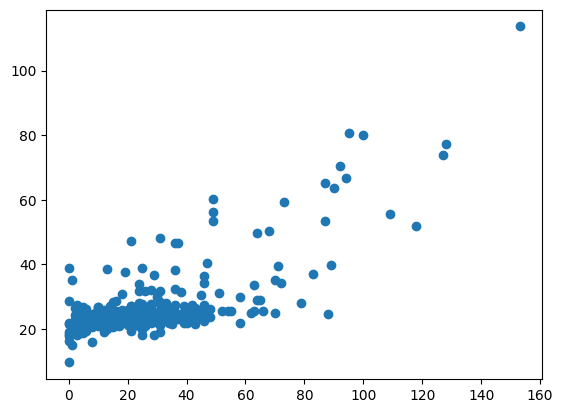

In [246]:
plt.scatter(y, y_pred)